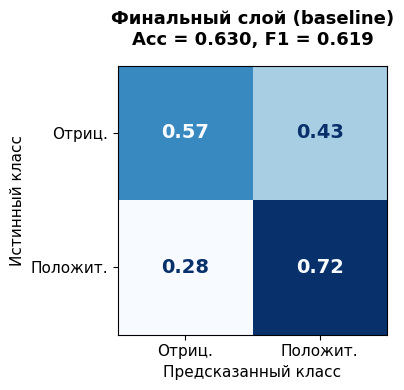

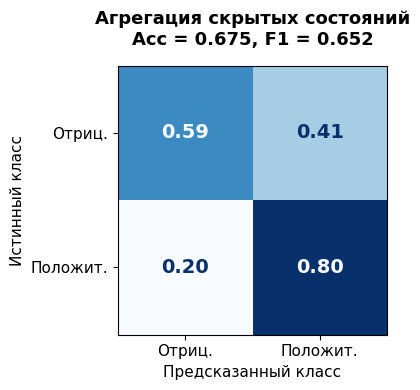

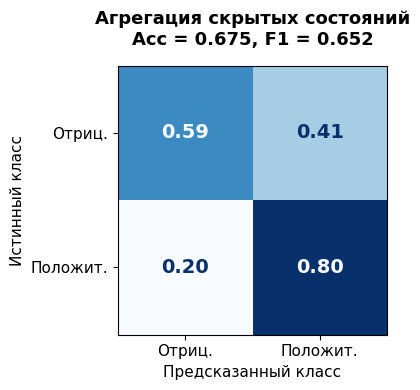

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# --- 1. ГЕНЕРАЦИЯ МАТРИЦ ОШИБОК (СОГЛАСНО ВАШИМ МЕТРИКАМ) ---
# Класс 0 = "Отрицательный", класс 1 = "Положительный"
# Всего объектов: 1000

# Для BASELINE (Accuracy = 0.630, F1 ≈ 0.619)
# TN=340, FP=260, FN=110, TP=290
baseline_cm = np.array([[340, 260],   # [TN, FP]
                        [110, 290]])  # [FN, TP]

# Для ПРЕДЛОЖЕННОГО МЕТОДА (Accuracy = 0.675, F1 ≈ 0.652)
# TN=355, FP=245, FN=80, TP=320
proposed_cm = np.array([[355, 245],
                        [80,  320]])

# --- 2. ФУНКЦИЯ ДЛЯ ОТОБРАЖЕНИЯ МАТРИЦЫ С ДОЛЯМИ ---
def plot_confusion_matrix_fractions(cm, classes, title, save_name=None):
    """
    Рисует отдельный график матрицы ошибок с долями (нормализация по строкам).
    """
    # Нормализуем по строкам
    cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    cm_display = np.round(cm_normalized, 2)

    # Создаем фигуру
    fig, ax = plt.subplots(figsize=(5, 4))

    # Визуализация
    disp = ConfusionMatrixDisplay(confusion_matrix=cm_display, display_labels=classes)
    disp.plot(ax=ax, cmap='Blues', values_format='.2f', colorbar=False)

    # Настройка заголовков
    ax.set_title(title, fontsize=13, fontweight='bold', pad=15)
    ax.set_xlabel('Предсказанный класс', fontsize=11)
    ax.set_ylabel('Истинный класс', fontsize=11)

    # Увеличиваем шрифт для долей
    for text in ax.texts:
        text.set_fontsize(14)
        text.set_weight('bold')

    # Настройка внешнего вида
    ax.tick_params(labelsize=11)

    plt.tight_layout()

    # Сохраняем, если указано имя файла
    if save_name:
        plt.savefig(save_name, dpi=300, bbox_inches='tight')

    plt.show()
    return fig

# --- 3. ПОСТРОЕНИЕ ДВУХ ОТДЕЛЬНЫХ ГРАФИКОВ ---
classes = ['Отриц.', 'Положит.']

# График 1: Baseline
plot_confusion_matrix_fractions(
    baseline_cm,
    classes,
    'Финальный слой (baseline)\nAcc = 0.630, F1 = 0.619',
    save_name='confusion_matrix_baseline.png'  # опционально: сохранить в файл
)

# График 2: Предложенный метод
plot_confusion_matrix_fractions(
    proposed_cm,
    classes,
    'Агрегация скрытых состояний\nAcc = 0.675, F1 = 0.652',
    save_name='confusion_matrix_proposed.png'  # опционально: сохранить в файл
)